<a href="https://colab.research.google.com/github/cbishop4/MSE7530/blob/main/ClassNotebooks/F2026/Lecture19_DiffE_InClass_20261118.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font size=6>Differential Evolution for Sphere fitting

<font size=4>The physical focus of this assignment will be X-ray scattering from non-crystalline materials. The Python focus will be the SciPy.special module, linear fitting, and optimization with SciPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

In [2]:
!rm -r MSE7530
! git clone https://github.com/cbishop4/MSE7530/

rm: cannot remove 'MSE7530': No such file or directory
Cloning into 'MSE7530'...
remote: Enumerating objects: 1122, done.
remote: Counting objects: 100% (257/257), done.
remote: Compressing objects: 100% (194/194), done.
remote: Total 1122 (delta 184), reused 62 (delta 62), pack-reused 865 (from 1)
Receiving objects: 100% (1122/1122), 204.52 MiB | 13.11 MiB/s, done.
Resolving deltas: 100% (462/462), done.
Updating files: 100% (378/378), done.


# Form factor Scattering

## Plotting scattering from analytical particle morphologies
<font size=4>As described in the textbook, there are only* 3 particle shapes that it is possible to analytically describe form factor scattering: spheres, discs, and rods. Below are the 3 equations entered as user-defined functions, using the Bessel and sine integral functions from the scipy.special module.

<font size=4>For a sphere:  
$\mathcal{F}(Q) = \frac{1}{V_{p}}\int_0^R\int_0^{2\pi}\int_0^\pi e^{iQrcos~\theta}r^{2}sin~\theta d\theta d\phi dr$  


<font size=4>$ = \frac{1}{V_{p}}\int_0^R 4\pi \frac{sin(Qr)}{Qr}r^2dr$  


<font size=5>$ = 3[\frac{sin(QR) - QRcos(QR)}{Q^{3}R^{3}}] \equiv \frac{3J_{1}(QR)}{QR}$

In [3]:
# def FQ2_sphere(radius, q): # scipy Bessel function is not reproducing correct result; what's happening?
#   return (3*special.jv(1,q*radius) / (q*radius))**2
def FQ2_sphere(radius, q):
  return (3*((np.sin(q*radius)- q*radius*np.cos(q*radius)))/(q**3 * radius**3))**2
def FQ2_disc(radius, q):
  return 2 * (1 - (special.jv(1,2*q*radius)/(q*radius)) ) / (q**2 * radius**2)

## Polydispersity
<font size=4> In the textbook, the function for calculating polydispersity is given by  
$I(Q) = \Delta \rho^{2} \int_{0}^{\infty} D(R)V_{p}(R)^{2}|\mathcal{F}(Q,R)|^{2} ~ dR $

<font size=4> We can calculate this by summing multiple form factors. Take that for a sphere:

[]

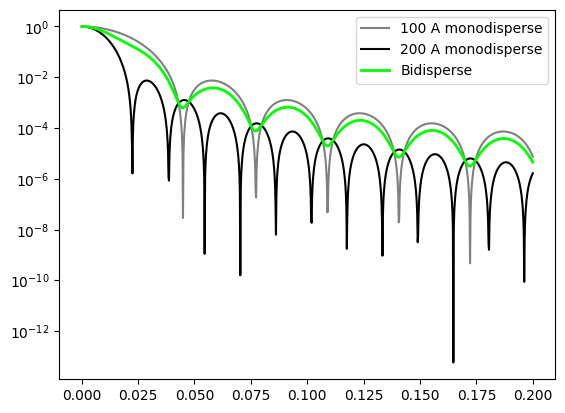

In [4]:
qrange = np.linspace(0.0001, 0.2,1000)
mono100 = FQ2_sphere(100.,qrange)
plt.plot(qrange,mono100,label='100 A monodisperse',color='grey')
mono200 = FQ2_sphere(200.,qrange)
plt.plot(qrange,mono200,label='200 A monodisperse',color='black')
bidisperse = (mono100 + mono200)/2
plt.plot(qrange,bidisperse,label='Bidisperse',color='lime',linewidth=2)
plt.legend()
plt.semilogy()

<font size=4> With increasing polydispersity, we very quickly smear out the scattering. Let's do this for 8 particle sizes:

Text(0.5, 1.0, '8 particle sizes, 50-800 nm')

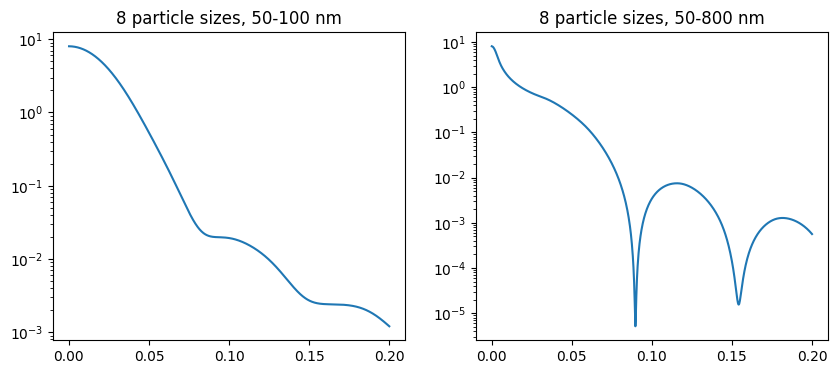

In [5]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
particle_sizes = np.linspace(50.,100.,8)
scatter = np.zeros(len(qrange))
for p in particle_sizes:
  scatter += FQ2_sphere(p, qrange)
# now the same number of particle sizes, but a larger dispersity
scatter2 = np.zeros(len(qrange))
particle_sizes2 = np.linspace(50.,800.,8)
for p in particle_sizes2:
  scatter2 += FQ2_sphere(p, qrange)

ax[0].plot(qrange,scatter)
ax[1].plot(qrange,scatter2)
for a in ax:
  a.semilogy()
ax[0].set_title('8 particle sizes, 50-100 nm')
ax[1].set_title('8 particle sizes, 50-800 nm')


### Pulling more realistic distributions (+ Python skills)  
<font size=4> To make a more realistic solution, we will pull particle sizes from a normal distribution. To do this, we will use the NumPy random module. (https://numpy.org/doc/2.1/reference/random/generated/numpy.random.normal.html)

<font size=4>A Gaussian is defined by the equation for the probability distribution $p(x)$:  
<font size=4>$p(x) = \frac{1}{\sqrt{2\pi \sigma ^{2}}} e^{- \frac{(x - \mu)^{2}}{2 \sigma ^{2}}} $

<font size=4>We can use the np.random.normal function to choose a specified number of random numbers pulled with that probability. If we pull a sufficient number of samples, it should look like a Gaussian. Below we pull 3 different distributions with the same mean ($\mu$ above, given by the parameter "loc" in the code) and standard deviation ($\sigma$ above, given by "scale"), but with increasing numbers of samples (in code, "size") to see the effect of sampling on the generated distribution. After generating each, we plot a histogram of the values.

Text(0.5, 1.0, '10,000 samples')

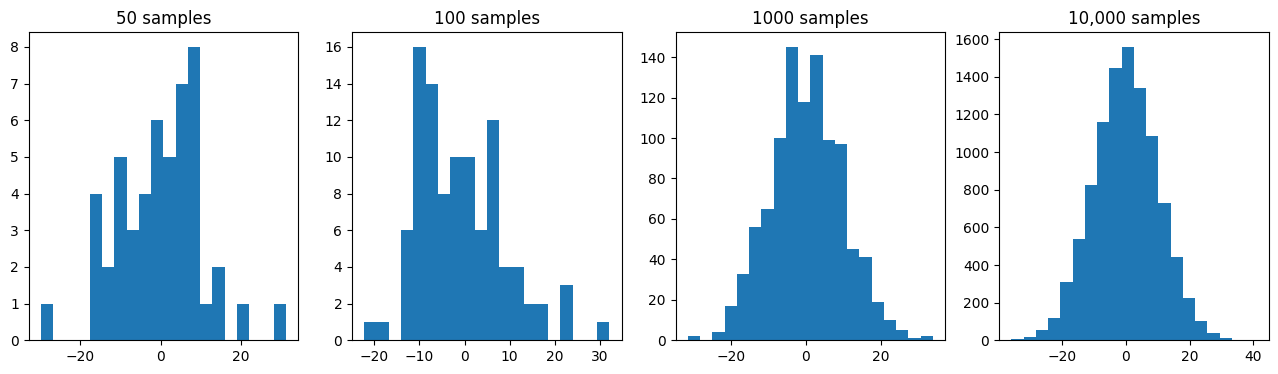

In [6]:
fig, ax = plt.subplots(1,4,figsize=(16,4))
distro1 = np.random.normal(loc=0, scale=10, size=50)
distro2 = np.random.normal(loc=0, scale=10, size=100)
distro3 = np.random.normal(loc=0, scale=10, size=1000)
distro4 = np.random.normal(loc=0, scale=10, size=10000)
ax[0].hist(distro1,bins=20)
ax[1].hist(distro2,bins=20)
ax[2].hist(distro3,bins=20)
ax[3].hist(distro4,bins=20)
ax[0].set_title('50 samples')
ax[1].set_title('100 samples')
ax[2].set_title('1000 samples')
ax[3].set_title('10,000 samples')

Note that if you run the cell above multiple times, the results change. To make the results from a single notebook/script reproducible, we can use a "random seed". This sets the random generator to a specified state so that every time you run the notebook, it will generate random numbers reproducibly. **You should always do this when you use a random function**.


```
np.random.seed(seed=30)
```



Text(0.5, 1.0, '10,000 samples')

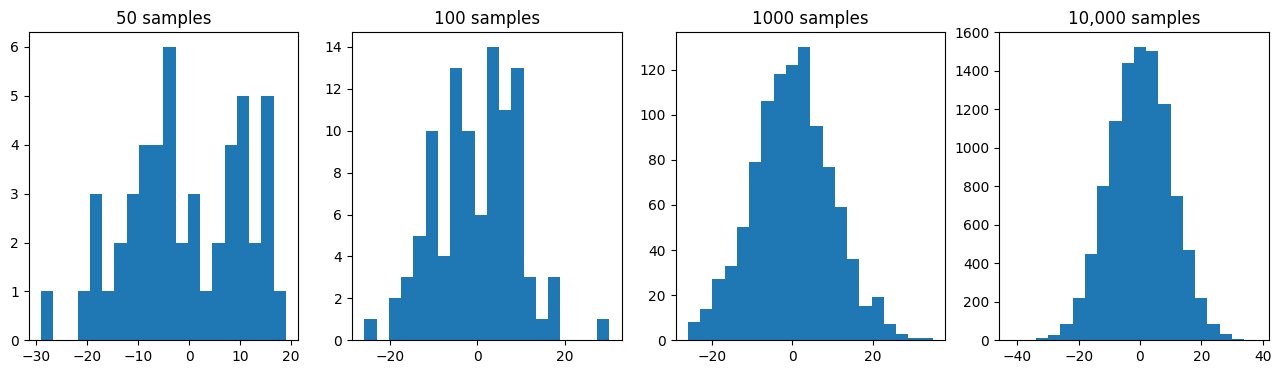

In [7]:
np.random.seed(seed=30)
fig, ax = plt.subplots(1,4,figsize=(16,4))
distro1 = np.random.normal(loc=0, scale=10, size=50)
distro2 = np.random.normal(loc=0, scale=10, size=100)
distro3 = np.random.normal(loc=0, scale=10, size=1000)
distro4 = np.random.normal(loc=0, scale=10, size=10000)
ax[0].hist(distro1,bins=20)
ax[1].hist(distro2,bins=20)
ax[2].hist(distro3,bins=20)
ax[3].hist(distro4,bins=20)
ax[0].set_title('50 samples')
ax[1].set_title('100 samples')
ax[2].set_title('1000 samples')
ax[3].set_title('10,000 samples')

Now, it will make the same distributions every time so you can exactly reproduce results from everyone's notebooks

<font size=4> Applying the distribution to polydispersity.  
Different processes (for example, polymerizations) can lead to different distributions of particle sizes in solution. Different distributions can lead to nearly identical scattering, so you will often need complementary characterization.

Text(0, 0.5, '$|F(Q)|^{2}$')

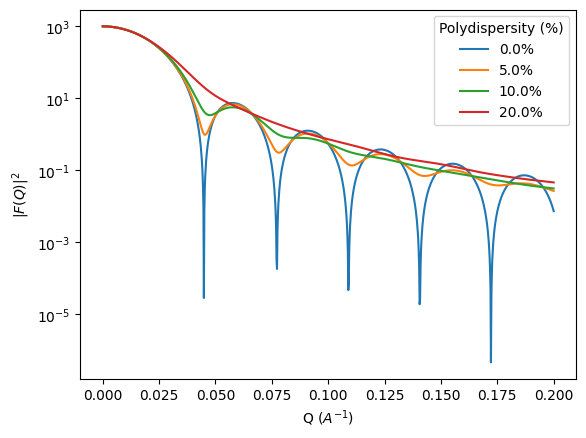

In [8]:
fig, ax = plt.subplots()
dispersities = np.asarray([0., .05, .1, .2])

radius = 100.
for d in dispersities:
  np.random.seed(seed=30)
  particle_sizes = np.random.normal(loc=radius, scale=radius*d, size=1000)
  scatter = np.zeros(len(qrange))
  for p in particle_sizes:
    scatter += FQ2_sphere(p, qrange)
  ax.plot(qrange,scatter, label=f'{d*100}%')

ax.semilogy()
ax.legend(title='Polydispersity (%)')
ax.set_xlabel('Q ($A^{-1}$)')
ax.set_ylabel('$|F(Q)|^{2}$')


Text(0.5, 1.0, 'Bi-modal system')

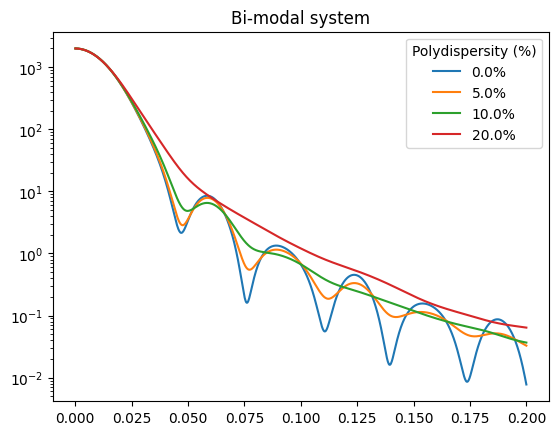

In [9]:
fig, ax = plt.subplots()
dispersities = np.asarray([0., .05, .1, .2])
radius1 = 100.
radius2 = 150.
for d in dispersities:
  np.random.seed(seed=50)
  particle_sizes1 = np.random.normal(loc=radius1, scale=radius1*d, size=1000)
  particle_sizes2 = np.random.normal(loc=radius2, scale=radius1*d, size=1000)
  all_particles = np.append(particle_sizes1,particle_sizes2)
  scatter = np.zeros(len(qrange))
  for p in all_particles:
    scatter += FQ2_sphere(p, qrange)
  ax.plot(qrange,scatter, label=f'{d*100}%')

ax.semilogy()
ax.legend(title='Polydispersity (%)')
ax.set_title('Bi-modal system')

<font size=4> Polydispersity can make it quite difficult to find unique solutions. One way to more powerfully search for real-space solutions is with a genetic algorithm, which you will do later in the homework questions.

Differential Evolution Walkthrough.
<font size=4> Differential evolution is another evolutionary algorithm that is slightly distinct from the Genetic Algorithm.

<font size=4> This will follow a very similar workflow to the first step of CREASE. The question we will answer here is: Given a scattering pattern, can we uniquely find the radius and polydispersity at the same time?

<font size=4> "Simulated Experiment" - Generating our objective function ($I_{exp} (q)$).

Text(0.5, 0, 'Q ($A^{-1}$)')

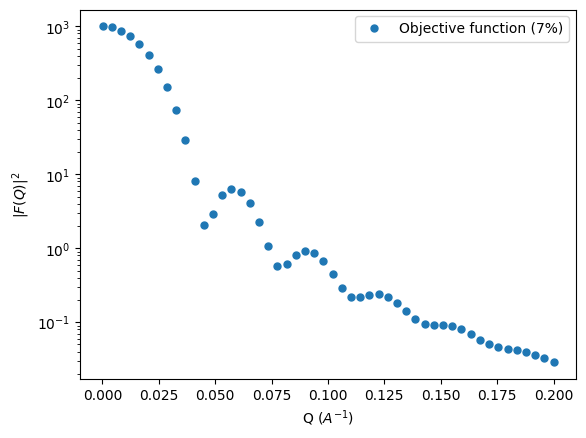

In [10]:
# prepare the "known" scattering
fig, ax = plt.subplots()
qrange = np.linspace(0.0001, 0.2,1000)
qrange_exp = np.linspace(0.0001, 0.2,50)
dispersity=0.07
radius = 100.
particle_sizes = np.random.normal(loc=radius, scale=radius*dispersity, size=1000)
I_exp = np.zeros(len(qrange_exp))
for p in particle_sizes:
    I_exp += FQ2_sphere(p, qrange_exp)
ax.plot(qrange_exp,I_exp,'o',markersize=5,label='Objective function (7%)')

ax.semilogy()
ax.legend()
ax.set_ylabel('$|F(Q)|^{2}$')
ax.set_xlabel('Q ($A^{-1}$)')

<font size=4> Setting up the genetic algorithm (differential evolution).
As an argument, differential_evolution takes some function to optimize. In this case, the function:
1. Generates a range of particle sizes from a specified radius and polydispersity percentage. "Loc" corresponds to the mean size of particles in the distribution, and the "scale" corresponds to the full-width at half-max of the distribution.  
2. The "for p in particle_sizes:" loop calculates the form factor scattering for each sphere in the distribution and sums it together into $I_{comp}$.
3. The "MSE" step calculates the error between the experimental (what we simulated) and the current guess data. Note that I have done this on the $log_{10}$ data; it wasn't converging when I did it linearly.

In [11]:
def gen_scatter(x):
  ''' A function that calculates the MSE for simulated scattering from a
      specified radius and polydispersity and compares it to known scattering

      Args:
        x (array or list) : a list of parameters corresponding to [radius, polydispersity]

      Returns:
        MSE (float) : the mean squared error between the simulated and known scattering
  '''
  np.random.seed(42) # seed so we have the same scattering every time
  qrange = np.linspace(0.0001, 0.2,50)
  dispersity=0.07
  radius = 100. # these are for our I_exp
  particle_sizes = np.random.normal(loc=radius, scale=radius*dispersity, size=1000)
  I_exp = np.zeros(len(qrange))
  for p in particle_sizes:
      I_exp += FQ2_sphere(p, qrange)
  # the next line is what we will randomly generate in each step of the GA evaluation
  particle_sizes = np.random.normal(loc=x[0], scale=x[0]*x[1], size=1000)
  I_comp = np.zeros(len(qrange))
  for p in particle_sizes:
      I_comp += FQ2_sphere(p, qrange)
  MSE = np.mean((np.log10(I_comp) - np.log10(I_exp))**2)
  print(f'{x[0]}, {x[1]}, {MSE}')
  return MSE

<font size=4> Now we will run our differential evolution (a type of genetic algorithm). Below I set it up. Be reassured that it should take 1-3 minutes to run.

In [12]:
from scipy import optimize

In [13]:
pd_min, pd_max = 0.06, 0.08 # sets the upper and lower bounds on polydispersities to test
r_min, r_max = 50., 300. # sets maximum and minimum mean particle radius
bounds = [(r_min,r_max),(pd_min,pd_max)]
np.random.seed(10)
result4 = optimize.differential_evolution(gen_scatter, bounds, tol = 0.01)

192.42049457725756, 0.0682893426622222, 1.2639030076758548
84.7425903046878, 0.06973402596893637, 0.14105814740987233
153.68194312019165, 0.06272555987611601, 0.5958964682159231
291.56354562418227, 0.06552791737878043, 3.294509756372672
115.10517468043429, 0.06507501737788626, 0.11527808142323336
100.03290221939929, 0.07592262431970746, 0.0006048815796111585
252.7125969819354, 0.0690087588283696, 2.4638168041877577
137.85453640009385, 0.07743410134642839, 0.34751608432277414
298.5510236986895, 0.06116586925502575, 3.443708761582962
226.65789616399007, 0.07611001059847944, 1.9270309297919404
244.1330142239973, 0.0730841914322076, 2.277995884719467
236.2637719952674, 0.07034776476826243, 2.129064317025381
70.82089176918825, 0.06676144669840102, 0.4119564716789331
278.2009537391017, 0.07457123353497183, 3.004702960645133
181.71019330693957, 0.07950091608947138, 1.034244411051827
208.72413599491043, 0.06778275574337757, 1.5849202497579344
172.08664318276223, 0.07862950714149254, 0.85774379

<font size=4> Unfortunately, it is actually quite difficult to print out the progress of a differential evolution during its evaluation. By hand, I copy-pasted the above printed results into excel, used "Text to Columns", saved the excel file, and uploaded it to the class repo. We retrieve it below so you can graphically see the results.

In [14]:
import pandas as pd
diffE_res4 = pd.read_excel('/content/MSE7530/sampledata/HW4/diffE_result4.xlsx',header=None, names=['R','PD','MSE'])

Text(0, 0.5, 'MSE')

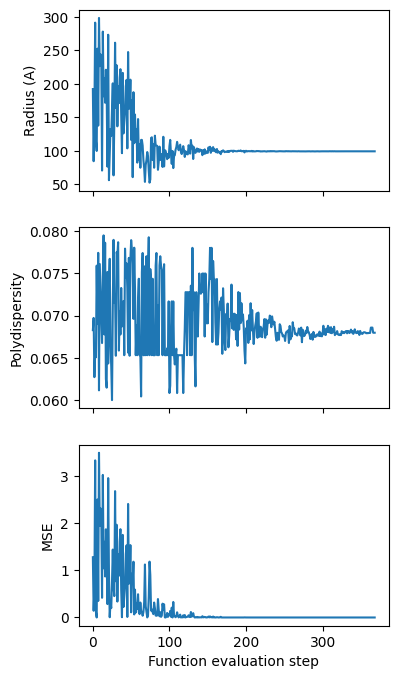

In [15]:
fig, ax = plt.subplots(3,1,figsize=(4,8),sharex=True)
ax[0].plot(diffE_res4['R'])
ax[1].plot(diffE_res4['PD'])
ax[2].plot(diffE_res4['MSE'])
ax[2].set_xlabel('Function evaluation step')
ax[0].set_ylabel('Radius (A)')
ax[1].set_ylabel('Polydispersity')
ax[2].set_ylabel('MSE')


Using our result (result4), we plot the fit results over the (simulated) experimental data.

Text(0.5, 0, 'Q ($A^{-1}$)')

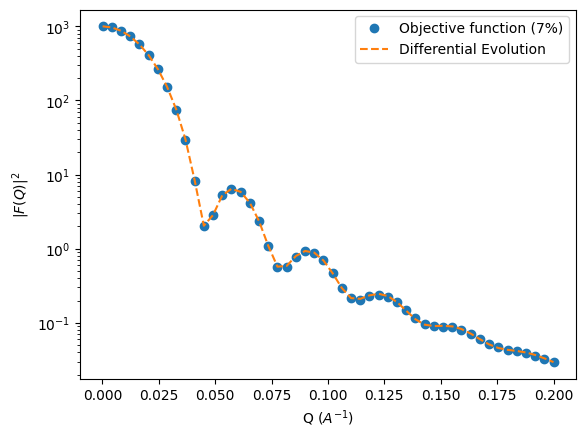

In [16]:
# prepare the "known" scattering
fig, ax = plt.subplots()
np.random.seed(42)
qrange = np.linspace(0.0001, 0.2,50)
dispersity=0.07
radius = 100.
particle_sizes = np.random.normal(loc=radius, scale=radius*dispersity, size=1000)
I_exp = np.zeros(len(qrange))
for p in particle_sizes:
    I_exp += FQ2_sphere(p, qrange)
ax.plot(qrange,I_exp,'o',label='Objective function (7%)')
particle_sizes = np.random.normal(loc=result4['x'][0], scale=result4['x'][0]*result4['x'][1], size=1000)
I_solved = np.zeros(len(qrange))
for p in particle_sizes:
    I_solved += FQ2_sphere(p, qrange)
ax.plot(qrange,I_solved,label='Differential Evolution',linestyle='--')


ax.semilogy()
ax.legend()
ax.set_ylabel('$|F(Q)|^{2}$')
ax.set_xlabel('Q ($A^{-1}$)')

### a) Which parameter - radius or polydispersity - has the biggest effect on the MSE? How can you tell from the graphs? Qualitatively, why does it have a bigger effect on the MSE?

<font color='red'> [Written Answer Here]

### b) Where does the fit seem to be the best - at low or high values of Q? Thinking about how error is calculated, why might this be?

<font color='red'> [Written Answer Here]